# Entanglement Generation — GHZ State — CUDA-Q Implementation

**Primitive:** GHZ-state generation (maximal 3-qubit entanglement) via H + CNOT chain

**SETUP (must match the Qiskit notebook exactly for results to line up)**
- N QUBITS: 3
- GATE SEQUENCE: H(q0), then CX(control=q0, target=q1), then CX(control=q1, target=q2)
- QUBIT ORDERING (contract): qubit 0 = rightmost bit in printed bitstring
- SHOTS: 10000, SEED: 42
- GLOBAL PHASE: normalized so first nonzero amplitude (ascending bitstring order) is real and positive
- Basis ordering for matrices: {|000>, |001>, ..., |111>} (ascending binary order)

**Theory recap:** identical to the Qiskit version -- H(q0) creates a superposition, then the
CX chain CX(q0,q1) -> CX(q1,q2) propagates it into the maximally entangled GHZ state
|GHZ> = (|000> + |111>) / sqrt(2).

**Important ordering warning:** CUDA-Q's native state-vector indexing treats qubit 0 as the
**most-significant** bit (opposite of Qiskit's rightmost/least-significant convention). This
notebook explicitly reverses bit order after extracting the state so the final printed
dictionary matches the SETUP convention and is directly diffable against `QISKIT_RESULT`.
For THIS specific state the reversal happens to be a no-op numerically (|000> and |111> are
each palindromic bitstrings), but the reindexing code is still applied explicitly so the
method generalizes to non-symmetric circuits.

**IMPORTANT: Run every cell in order, top to bottom** (Kernel -> Restart & Run All).

In [1]:
# Run this cell first if you get ModuleNotFoundError.
# Correct package name is "cudaq" (NOT "cuda-quantum" -- that name has no prebuilt wheel and breaks pip).
# Requires pip >= 24.0, and Linux (x86_64/aarch64) or macOS (arm64/Apple Silicon). Windows needs WSL.
!pip install --upgrade pip -q
!pip install -q cudaq
# Restart the kernel after this finishes (Kernel -> Restart Kernel), then Run All.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 7.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import cudaq

N_QUBITS = 3
SHOTS = 10000
SEED = 42

cudaq.set_random_seed(SEED)

print(f"N_QUBITS={N_QUBITS}, SHOTS={SHOTS}, SEED={SEED}")
print("Gate sequence: H(q0) -> CX(control=q0, target=q1) -> CX(control=q1, target=q2)")

N_QUBITS=3, SHOTS=10000, SEED=42
Gate sequence: H(q0) -> CX(control=q0, target=q1) -> CX(control=q1, target=q2)


## 1. Build the kernel explicitly, gate by gate

In [3]:
@cudaq.kernel
def ghz_state_kernel():
    q = cudaq.qvector(3)
    h(q[0])             # Put qubit 0 into an equal superposition of |0> and |1>
    x.ctrl(q[0], q[1])  # Entangle qubit 1 with qubit 0
    x.ctrl(q[1], q[2])  # Propagate the correlation to qubit 2

**Note:** CUDA-Q expresses a controlled-X (CNOT) as `x.ctrl(control, target)`, unlike
Qiskit's `qc.cx(control, target)` method call -- same gate, different API spelling. No
kernel arguments are needed since the gate sequence has no continuous parameters.

## 2. Draw/visualize the circuit

In [4]:
# Native CUDA-Q text drawing
print(cudaq.draw(ghz_state_kernel))

     ╭───╮          
q0 : ┤ h ├──●───────
     ╰───╯╭─┴─╮     
q1 : ─────┤ x ├──●──
          ╰───╯╭─┴─╮
q2 : ──────────┤ x ├
               ╰───╯



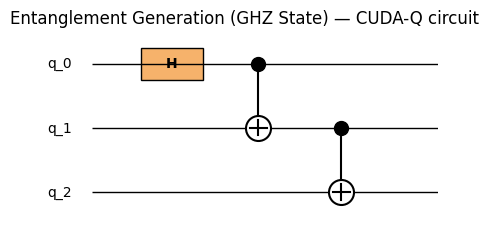

In [5]:
# Matplotlib circuit diagram, styled to resemble the Qiskit mpl output
fig, ax = plt.subplots(figsize=(5, 2.5))

wire_labels = [f"q_{i}" for i in range(N_QUBITS)]
for i, label in enumerate(wire_labels):
    y = N_QUBITS - 1 - i
    ax.hlines(y, 0, 5, color="black", linewidth=1)
    ax.text(-0.3, y, label, va="center", ha="right", fontsize=10)

y0 = N_QUBITS - 1 - 0  # row for q0
y1 = N_QUBITS - 1 - 1  # row for q1
y2 = N_QUBITS - 1 - 2  # row for q2

def draw_cx(ax, x, y_control, y_target):
    ax.vlines(x, min(y_control, y_target), max(y_control, y_target), color="black", linewidth=1.5)
    ax.plot(x, y_control, marker="o", markersize=10, color="black")
    ax.plot(x, y_target, marker="o", markersize=18, markerfacecolor="white", markeredgecolor="black", markeredgewidth=1.5)
    ax.plot([x - 0.12, x + 0.12], [y_target, y_target], color="black", linewidth=1.5)
    ax.plot([x, x], [y_target - 0.12, y_target + 0.12], color="black", linewidth=1.5)

# H box on q0
ax.add_patch(plt.Rectangle((0.7, y0 - 0.25), 0.9, 0.5, facecolor="#f6b26b", edgecolor="black"))
ax.text(1.15, y0, "H", va="center", ha="center", fontsize=10, fontweight="bold")

# CX(q0, q1)
draw_cx(ax, 2.4, y0, y1)

# CX(q1, q2)
draw_cx(ax, 3.6, y1, y2)

ax.set_xlim(-0.6, 5)
ax.set_ylim(-0.5, N_QUBITS - 0.5)
ax.axis("off")
ax.set_title("Entanglement Generation (GHZ State) \u2014 CUDA-Q circuit")

fig.savefig("ghz_state_cudaq_circuit.png", bbox_inches="tight")
fig

## 3. Explicit matrix representation of the key operator(s)

In [6]:
# --- (a) Hand-built full unitary via generic gate-embedding functions -- identical convention
# and identical helper functions to the Qiskit notebook ---
H_gate = (1 / np.sqrt(2)) * np.array([[1, 1],
                                       [1, -1]], dtype=complex)
print("H matrix:")
print(np.round(H_gate, 4))

def apply_1q(state, gate, q, n):
    dim = 2 ** n
    new = np.zeros(dim, dtype=complex)
    for idx in range(dim):
        bit = (idx >> q) & 1
        base = idx & ~(1 << q)
        for new_bit in range(2):
            amp = gate[new_bit, bit]
            if amp == 0:
                continue
            new[base | (new_bit << q)] += amp * state[idx]
    return new

def apply_cx(state, control, target, n):
    dim = 2 ** n
    new = np.zeros(dim, dtype=complex)
    for idx in range(dim):
        out_idx = idx ^ (1 << target) if (idx >> control) & 1 else idx
        new[out_idx] = state[idx]
    return new

def run_circuit_statevector(initial_state, n):
    state = initial_state.copy()
    state = apply_1q(state, H_gate, 0, n)
    state = apply_cx(state, 0, 1, n)
    state = apply_cx(state, 1, 2, n)
    return state

dim = 2 ** N_QUBITS
U_hand = np.zeros((dim, dim), dtype=complex)
for col in range(dim):
    basis = np.zeros(dim, dtype=complex)
    basis[col] = 1
    U_hand[:, col] = run_circuit_statevector(basis, N_QUBITS)

print(f"\nFull {dim}x{dim} circuit unitary U (hand-built, basis {{|000>,...,|111>}}, same")
print("convention as the Qiskit notebook):")
print(np.round(U_hand, 4))

unitary_ok = np.allclose(U_hand.conj().T @ U_hand, np.eye(dim), atol=1e-8)
print(f"\nU is unitary (U-dagger . U == I): {unitary_ok}")
assert unitary_ok, "Hand-built matrix is not unitary -- gate embedding logic has a bug!"

H matrix:
[[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]

Full 8x8 circuit unitary U (hand-built, basis {|000>,...,|111>}, same
convention as the Qiskit notebook):
[[ 0.7071+0.j  0.7071+0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j
   0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.7071+0.j -0.7071+0.j  0.    +0.j  0.    +0.j
   0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j
   0.7071+0.j  0.7071+0.j]
 [ 0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.7071+0.j -0.7071+0.j
   0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.7071+0.j  0.7071+0.j
   0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j
   0.7071+0.j -0.7071+0.j]
 [ 0.    +0.j  0.    +0.j  0.7071+0.j  0.7071+0.j  0.    +0.j  0.    +0.j
   0.    +0.j  0.    +0.j]
 [ 0.7071+0.j -0.7071+0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j
   0.    +0.j  0.    +0.j]]

U is unitary (U-da

In [7]:
# --- (b) Cross-check: apply U_hand to |000> and compare against CUDA-Q's own get_state() (after reordering, step 4) ---
psi0 = np.zeros(dim, dtype=complex)
psi0[0] = 1.0
psi_hand = U_hand @ psi0
print("U applied to |000> (hand-built):")
print(np.round(psi_hand, 4))
print("(Cross-checked against cudaq.get_state() output in Section 4 below.)")

U applied to |000> (hand-built):
[0.7071+0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j
 0.    +0.j 0.7071+0.j]
(Cross-checked against cudaq.get_state() output in Section 4 below.)


## 4. Exact statevector, reordered + global-phase normalized

In [8]:
state = cudaq.get_state(ghz_state_kernel)
raw_amps = np.array(state)

print("Raw CUDA-Q amplitudes (native ordering, qubit0 = MSB):")
print(np.round(raw_amps, 4))

Raw CUDA-Q amplitudes (native ordering, qubit0 = MSB):
[0.7071+0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j
 0.    +0.j 0.7071+0.j]


In [9]:
# --- Explicit reindexing: CUDA-Q native (qubit0=MSB) -> SETUP convention (qubit0=rightmost/LSB) ---
def reorder_cudaq_to_qiskit_convention(amps, n_qubits):
    dim = 2 ** n_qubits
    reordered = np.zeros(dim, dtype=complex)
    for cudaq_index in range(dim):
        cudaq_bits = format(cudaq_index, f"0{n_qubits}b")   # qubit0 = MSB (CUDA-Q native)
        target_bits = cudaq_bits[::-1]                        # qubit0 = rightmost (SETUP)
        target_index = int(target_bits, 2)
        reordered[target_index] = amps[cudaq_index]
    return reordered

amps_reordered = reorder_cudaq_to_qiskit_convention(raw_amps, N_QUBITS)
print("Reordered amplitudes (qubit0 = rightmost, matches SETUP convention):")
print(np.round(amps_reordered, 4))

matches = np.allclose(amps_reordered, psi_hand, atol=1e-6)
print(f"\nMatches hand-built unitary applied to |000>: {matches}")
assert matches, "CUDA-Q statevector and hand-built matrix disagree -- check gate/ordering conventions!"

Reordered amplitudes (qubit0 = rightmost, matches SETUP convention):
[0.7071+0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j
 0.    +0.j 0.7071+0.j]

Matches hand-built unitary applied to |000>: True


In [10]:
# Global phase normalization -- identical method to the Qiskit notebook.
def normalize_global_phase(statevector_data, n_qubits):
    dim = 2 ** n_qubits
    bitstrings = [format(i, f"0{n_qubits}b") for i in range(dim)]
    order = np.argsort(bitstrings)
    for idx in order:
        amp = statevector_data[idx]
        if abs(amp) > 1e-9:
            phase = np.angle(amp)
            corrected = statevector_data * np.exp(-1j * phase)
            return corrected, bitstrings
    return statevector_data, bitstrings

amps_norm, bitstrings = normalize_global_phase(amps_reordered, N_QUBITS)

exact_probs = {}
for i, bs in enumerate(bitstrings):
    exact_probs[bs] = round(abs(amps_norm[i]) ** 2, 4)

exact_probs = dict(sorted(exact_probs.items()))
print("Exact statevector amplitudes (phase-normalized):")
print(np.round(amps_norm, 4))
print()
print("Exact statevector probabilities (qubit0 = rightmost):")
print(exact_probs)

Exact statevector amplitudes (phase-normalized):
[0.7071+0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j
 0.    +0.j 0.7071+0.j]

Exact statevector probabilities (qubit0 = rightmost):
{'000': np.float64(0.5), '001': np.float64(0.0), '010': np.float64(0.0), '011': np.float64(0.0), '100': np.float64(0.0), '101': np.float64(0.0), '110': np.float64(0.0), '111': np.float64(0.5)}


## 5. Measurement: sample, plot histogram

In [11]:
result = cudaq.sample(ghz_state_kernel, shots_count=SHOTS)
raw_counts = {bs: result.count(bs) for bs in result}
print("Raw CUDA-Q counts (native bitstring ordering, qubit0 = MSB):")
print(raw_counts)

Raw CUDA-Q counts (native bitstring ordering, qubit0 = MSB):
{'111': 5053, '000': 4947}


In [12]:
# Reverse each sampled bitstring the same way as the statevector, to match SETUP convention
sampled_probs = {}
for bs, c in raw_counts.items():
    reordered_bs = bs[::-1]
    sampled_probs[reordered_bs] = sampled_probs.get(reordered_bs, 0) + c

sampled_probs = {bs: round(c / SHOTS, 4) for bs, c in sampled_probs.items()}
sampled_probs = dict(sorted(sampled_probs.items()))
print(f"Sampled probabilities ({SHOTS} shots, seed={SEED}), qubit0 = rightmost:")
print(sampled_probs)

Sampled probabilities (10000 shots, seed=42), qubit0 = rightmost:
{'000': 0.4947, '111': 0.5053}


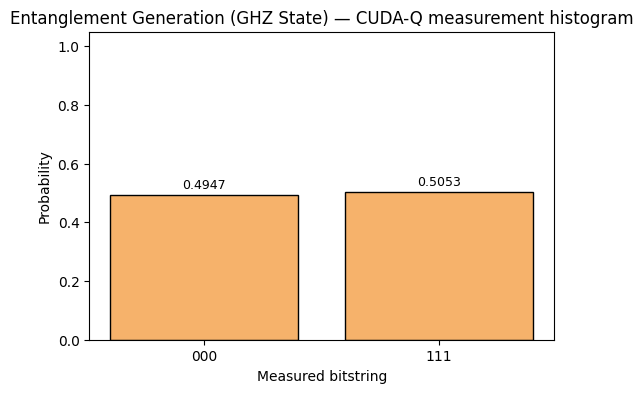

In [13]:
# Matplotlib bar chart styled like Qiskit's plot_histogram()
fig2, ax2 = plt.subplots(figsize=(6, 4))
labels = list(sampled_probs.keys())
values = list(sampled_probs.values())

ax2.bar(labels, values, color="#f6b26b", edgecolor="black")
ax2.set_xlabel("Measured bitstring")
ax2.set_ylabel("Probability")
ax2.set_title("Entanglement Generation (GHZ State) \u2014 CUDA-Q measurement histogram")
ax2.set_ylim(0, 1.05)
for i, v in enumerate(values):
    ax2.text(i, v + 0.02, str(v), ha="center", fontsize=9)

fig2.savefig("ghz_state_cudaq_histogram.png", bbox_inches="tight")
fig2

## 6. Gate / operation count

In [14]:
gate_count = 3  # one H + two CX
print(f"Gate/operation count: {gate_count}")

Gate/operation count: 3


## 7. Convention notes

In [15]:
print("Qubit ordering: CUDA-Q's cudaq.get_state() and cudaq.sample() natively index/report")
print("bitstrings with qubit 0 as the MOST-significant (leftmost) bit -- the opposite of Qiskit's")
print("convention. This notebook explicitly reversed every bitstring (both for the statevector")
print("amplitudes and the sampled counts) via string reversal / index remapping, so the final")
print("printed results use qubit 0 = rightmost, matching the SETUP convention and the Qiskit output.")
print("For this particular state the reversal is numerically a no-op (|000> and |111> are each")
print("palindromic), but the code path is identical to what a non-symmetric circuit needs.")
print()
print("Global phase: computed and removed using the identical method as the Qiskit notebook --")
print("first nonzero amplitude in ascending-bitstring order is rotated to be real and positive.")
print("For the GHZ state this is also a no-op: the |000> and |111> amplitudes are already real")
print("and positive (1/sqrt(2) each).")
print()
print("Entanglement check: this is genuine 3-body (GHZ-type) entanglement -- no two of the three")
print("qubits can be described independently of the third, unlike a Bell pair.")

Qubit ordering: CUDA-Q's cudaq.get_state() and cudaq.sample() natively index/report
bitstrings with qubit 0 as the MOST-significant (leftmost) bit -- the opposite of Qiskit's
convention. This notebook explicitly reversed every bitstring (both for the statevector
amplitudes and the sampled counts) via string reversal / index remapping, so the final
printed results use qubit 0 = rightmost, matching the SETUP convention and the Qiskit output.
For this particular state the reversal is numerically a no-op (|000> and |111> are each
palindromic), but the code path is identical to what a non-symmetric circuit needs.

Global phase: computed and removed using the identical method as the Qiskit notebook --
first nonzero amplitude in ascending-bitstring order is rotated to be real and positive.
For the GHZ state this is also a no-op: the |000> and |111> amplitudes are already real
and positive (1/sqrt(2) each).

Entanglement check: this is genuine 3-body (GHZ-type) entanglement -- no two of the th

## Final result (for diffing against QISKIT_RESULT)

In [16]:
CUDAQ_RESULT = exact_probs
print("CUDAQ_RESULT =", CUDAQ_RESULT)

CUDAQ_RESULT = {'000': np.float64(0.5), '001': np.float64(0.0), '010': np.float64(0.0), '011': np.float64(0.0), '100': np.float64(0.0), '101': np.float64(0.0), '110': np.float64(0.0), '111': np.float64(0.5)}


## Quick diff check
Run this after both notebooks have produced `QISKIT_RESULT` and `CUDAQ_RESULT`.
Expected (hand-computed): `{'000': 0.5, '001': 0.0, '010': 0.0, '011': 0.0, '100': 0.0, '101': 0.0, '110': 0.0, '111': 0.5}`

In [17]:
# QISKIT_RESULT = {'000': 0.5, '001': 0.0, '010': 0.0, '011': 0.0, '100': 0.0, '101': 0.0, '110': 0.0, '111': 0.5}  # paste from the Qiskit notebook
#
# all_keys = sorted(set(QISKIT_RESULT) | set(CUDAQ_RESULT))
# max_delta = max(abs(QISKIT_RESULT.get(k, 0) - CUDAQ_RESULT.get(k, 0)) for k in all_keys)
# print("Max probability delta:", max_delta)
# print("Match within tolerance:", max_delta < 1e-3)